# Алгоритмы машинного обучения
## Линейная и логистическая регрессия, деревья решений, случайный лес, градиентный бустинг, K-Means

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 3**

В этом материале мы рассматриваем, **как разные алгоритмы строят ответы**, чем отличаются их возможности и какие настройки влияют на поведение. Сначала обучим модели числового прогноза и классификации, затем отдельно рассмотрим K-Means для поиска групп без готовых ответов.

Ноутбук содержит выполненные примеры для занятия и самостоятельного чтения. Заданий нет. Перед каждой кодовой ячейкой дано введение, после неё — объяснение конструкций Python, методов и результата. Математические формулы и выводы не используются.

Данные создаются внутри файла, без скачивания. Названия и значения учебные: по ним нельзя делать выводы о реальных клиентах или бизнес-процессах. Табличные примеры маленькие и работают на обычном компьютере без видеокарты.

### Как работать с ноутбуком

Сохранённые таблицы и рисунки можно читать без запуска Python. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Ядро — процесс Python, который хранит переменные; ячейки связаны, поэтому выполняются сверху вниз.

Понадобятся Python, NumPy, Pandas, Matplotlib, scikit-learn и среда Jupyter. Установка пакетов из ноутбука не выполняется. Версии проверенной среды выводятся ниже.

Предобработка, метрики, переобучение и кросс-валидация уже разобраны в предыдущих файлах. Здесь используем эти инструменты и поясняем конкретные вызовы, но сосредоточимся на алгоритмах. Все настройки заданы для демонстрации заранее. Сравнения на одной валидационной части иллюстрируют поведение моделей и не устанавливают универсального победителя; отдельного финального тестирования в этом файле нет.

## 1. Карта алгоритмов и общий интерфейс

| Алгоритм | Какой ответ получаем | Основная идея |
|---|---|---|
| Линейная регрессия | Число | Одинаковое изменение одного признака даёт одинаковую добавку к прогнозу при неизменных остальных признаках |
| Логистическая регрессия | Класс и оценку принадлежности к классу | Объединяет вклады признаков и преобразует результат в оценки классов |
| Дерево решений | Класс или число | Последовательно задаёт вопросы о признаках и выдаёт ответ из достигнутого листа |
| Случайный лес | Класс или число | Объединяет ответы многих разнообразных деревьев |
| Градиентный бустинг | Класс или число | Последовательно добавляет модели, корректирующие текущий общий ответ |
| K-Means | Номер кластера | Распределяет объекты вокруг заданного количества центров |

**Алгоритм** определяет способ обучения, а **обученная модель** — полученное по конкретным данным состояние. В scikit-learn объект сначала создают, затем вызывают `fit`, после чего получают ответы методом `predict`. Конструктор задаёт настройки, но ещё не изучает примеры. Названия методов одинаковы у разных объектов, а смысл обучения зависит от алгоритма.

Слова `Regressor` и `Classifier` в именах классов библиотеки помогают отличать числовой прогноз от классификации. **LogisticRegression — классификатор**, несмотря на слово «регрессия» в историческом названии. K-Means не получает правильных классов при обучении.

Подключим инструменты и настроим отображение. Для каждой семьи деревьев импортируем и классификатор, и регрессор: так будет видно, что одна идея алгоритма может применяться к разным типам ответа. Непосредственное обучение начнётся в следующих разделах.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.13.13
NumPy: 2.4.6
Pandas: 2.3.3
Matplotlib: 3.10.9
scikit-learn: 1.8.0


**Разбор кода.**

- `import` подключает пакет или модуль. `as np`, `as pd`, `as plt` дают короткие имена NumPy, Pandas и модулю рисования Matplotlib. Точка в `matplotlib.pyplot` показывает вложенность. Запись `from ... import ...` подключает перечисленные инструменты непосредственно под их именами. Круглые скобки позволяют перенести длинный список на несколько строк; запятые разделяют элементы.
- NumPy нужен для массивов, Pandas — для таблиц, Matplotlib — для рисунков, scikit-learn — для алгоритмов и подготовки данных. `display` из IPython показывает таблицы в ноутбуке. Назначение отдельных импортированных классов и функций разбирается при использовании.
- `pd.set_option(...)` задаёт параметры отображения: число видимых столбцов и знаков после точки. Это не меняет точность хранимых данных. Текст в кавычках — строка, `12` и `3` — целые числа.
- `plt.rcParams` хранит настройки рисунков. Квадратные скобки выбирают настройку по ключу, `=` присваивает значение. Шрифт DejaVu Sans поддерживает кириллицу, `figure.dpi` задаёт плотность изображения.
- `print(...)` выводит текст и значения. `sys.version` содержит сведения о Python, `split()` разбивает строку по пробелам, `[0]` выбирает первый фрагмент. Позиции в Python начинаются с нуля. `.__version__` — атрибут с версией пакета.
- Точка выбирает атрибут или метод объекта. Круглые скобки после имени вызывают функцию или метод; запись без скобок читает значение или получает сам инструмент.

## 2. Линейная регрессия: общий тренд числового ответа

### Что именно подбирает модель

Возьмём учебную связь между числом позиций в заявке и длительностью её обработки. Линейная регрессия подбирает **коэффициенты** признаков и **свободный член**. Коэффициент показывает изменение прогноза при увеличении признака на одну единицу при неизменных остальных признаках. Свободный член задаёт значение модели при нулевых признаках; если нулей в обучении не было, его не следует автоматически считать реальным временем обработки пустой заявки.

При одном признаке график такого прогноза — прямая. В стандартном `LinearRegression` параметры подбираются так, чтобы сильнее учитывать крупные отклонения от известных ответов. Внутренние вычисления здесь не рассматриваем.

Модель удобна для общего тренда, но не умеет сама менять наклон на отдельных участках исходного признака. Коэффициент описывает найденную связь и **не доказывает причинное влияние**. Мы используем один признак для наглядности; класс поддерживает и несколько числовых признаков.

Создадим 120 наблюдений: для каждого размера заявки есть три условных измерения длительности. В исходных значениях после 24 позиций сделан скачок — так мы сможем увидеть, что одна прямая описывает не любую зависимость. Разделим признаки и ответы на общие обучающую и валидационную части для всех последующих регрессоров.

In [2]:
rng = np.random.default_rng(15)
base_minutes = np.array([
    10, 12, 11, 14, 15, 16, 17, 18, 20, 21,
    20, 23, 25, 24, 27, 28, 30, 29, 30, 32,
    33, 35, 36, 34, 51, 52, 54, 55, 58, 59,
    58, 61, 64, 63, 66, 68, 67, 69, 72, 73,
])
reg_features = pd.DataFrame({'Позиций в заявке': np.repeat(np.arange(1, 41), 3)})
reg_target = pd.Series(
    np.repeat(base_minutes, 3) + rng.normal(0, 1.5, size=120),
    name='Длительность, минуты',
)
X_reg_train, X_reg_valid, y_reg_train, y_reg_valid = train_test_split(
    reg_features, reg_target, test_size=0.3, random_state=21
)

display(pd.concat([reg_features, reg_target], axis=1).head(8))
print('Обучение:', len(X_reg_train), 'объекта; валидация:', len(X_reg_valid))

,Позиций в заявке,"Длительность, минуты"
0,1,7.854
1,1,8.595
2,1,10.591
3,2,11.214
4,2,12.788
5,2,13.211
6,3,8.835
7,3,12.526


Обучение: 84 объекта; валидация: 36


**Разбор кода и результата.**

- `np.random.default_rng(15)` создаёт генератор случайных чисел с фиксированным начальным значением. `rng.normal(0, 1.5, size=120)` создаёт 120 небольших отклонений вокруг нуля с заданным разбросом. Этот вызов имитирует различия измерений, а не обучает модель.
- `np.array([...])` превращает список исходных длительностей в массив. `np.arange(1, 41)` создаёт целые числа 1–40: правая граница не входит. `np.repeat(..., 3)` повторяет **каждый элемент** три раза. `+` складывает массивы по одинаковым позициям и добавляет отклонения к длительностям.
- `pd.DataFrame({...})` создаёт таблицу признаков из словаря. В словаре ключ слева от двоеточия — имя столбца, значение справа — его содержимое. `pd.Series(..., name=...)` создаёт один столбец ответов. Строки с одинаковой позицией в признаках и ответах относятся к одному наблюдению.
- `train_test_split(...)` разделяет признаки и ответы согласованно. При двух входах возвращаются четыре результата, которые распределяются по четырём именам слева от `=`. `test_size=0.3` выделяет 30% строк во вторую часть, `random_state=21` закрепляет перемешивание. Именованные аргументы записываются как `имя=значение` внутри вызова.
- `pd.concat([...], axis=1)` соединяет признаки и ответы рядом, по индексам строк. `head(8)` выбирает первые восемь строк, `display(...)` показывает таблицу, `len(...)` считает строки, `print(...)` выводит размеры.

Получились 84 обучающих и 36 валидационных наблюдений. Повторы размера здесь условно считаются отдельными независимыми измерениями. В реальных данных повторные записи одной заявки потребовали бы разделения по идентификатору заявки.

Обучим линейную регрессию по одному столбцу. Затем посмотрим на выученный коэффициент и свободный член. Эти параметры уже являются результатом обучения, в отличие от настроек, переданных при создании объекта.

In [3]:
linear_reg = LinearRegression()
linear_reg.fit(X_reg_train, y_reg_train)
linear_valid_predictions = linear_reg.predict(X_reg_valid)

display(pd.DataFrame({
    'Параметр': ['Коэффициент числа позиций', 'Свободный член'],
    'Значение': [linear_reg.coef_[0], linear_reg.intercept_],
}))
print('MAE на валидации, минуты:', round(mean_absolute_error(y_reg_valid, linear_valid_predictions), 3))

,Параметр,Значение
0,Коэффициент числа позиций,1.760
1,Свободный член,2.651


MAE на валидации, минуты: 3.151


**Разбор кода и результата.**

- `LinearRegression()` создаёт необученный объект. Пустые скобки означают, что используем стандартные настройки. `linear_reg` — имя переменной, в которой объект сохранён.
- `fit(X_reg_train, y_reg_train)` подбирает параметры по обучающим признакам и ответам. `predict(X_reg_valid)` возвращает по одному числовому прогнозу для каждой валидационной строки, не получая её правильный ответ.
- `.coef_` хранит коэффициенты, `[0]` выбирает единственный коэффициент; `.intercept_` — свободный член. Завершающее подчёркивание в таких атрибутах scikit-learn обычно обозначает результат обучения. `pd.DataFrame(...)` собирает параметры в таблицу, `display(...)` выводит её.
- `mean_absolute_error(...)` использует знакомую из предыдущего файла MAE: сначала факт, затем прогноз. `round(..., 3)` округляет отображаемое число до трёх знаков, `print(...)` печатает результат. Единицы ошибки здесь — минуты.

Положительный коэффициент означает: при увеличении числа позиций модель повышает прогноз длительности. Он описывает **одинаковую добавку** по всему диапазону. Модель не получила отдельного признака о скачке процесса после 24 позиций, поэтому не выделила его как самостоятельное правило.

В сохранённом выполнении коэффициент равен примерно 1,760: одна дополнительная позиция повышает прогноз модели примерно на 1,76 минуты по всему диапазону. Свободный член — около 2,651 минуты. MAE на валидации — около 3,151 минуты; это отдельная оценка по известным ответам, а не один из обученных коэффициентов.

Нарисуем обучающие и валидационные измерения, а поверх них — прогноз на ровной последовательности размеров заявки. Эта последовательность нужна для построения линии; она не используется в `fit` и не добавляет новых известных ответов.

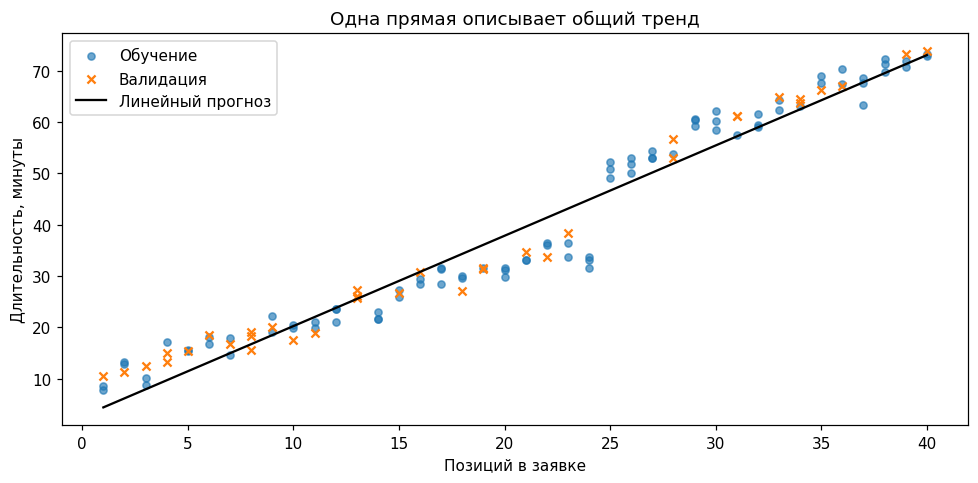

In [4]:
reg_grid = pd.DataFrame({'Позиций в заявке': np.linspace(1, 40, 160)})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(X_reg_train['Позиций в заявке'], y_reg_train, s=22, alpha=0.65, label='Обучение')
ax.scatter(X_reg_valid['Позиций в заявке'], y_reg_valid, s=28, marker='x', label='Валидация')
ax.plot(reg_grid['Позиций в заявке'], linear_reg.predict(reg_grid), color='black', label='Линейный прогноз')
ax.set_xlabel('Позиций в заявке')
ax.set_ylabel('Длительность, минуты')
ax.set_title('Одна прямая описывает общий тренд')
ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `np.linspace(1, 40, 160)` создаёт 160 равномерно расположенных значений, включая границы. `pd.DataFrame(...)` сохраняет то же имя входного столбца, с которым обучалась модель. Не следует произвольно менять состав и порядок входных признаков после обучения.
- `plt.subplots(figsize=(9, 4.5))` возвращает рисунок `fig` и область рисования `ax`. Запятая слева от `=` распределяет два результата. `(9, 4.5)` — кортеж размеров в дюймах.
- `scatter(...)` рисует точки по двум наборам значений. Квадратные скобки после таблицы выбирают столбец. `s` задаёт размер точек, `alpha` — непрозрачность, `marker='x'` — вид маркера, `label` — подпись в легенде.
- `plot(...)` рисует линию. `linear_reg.predict(reg_grid)` получает её высоту, `color='black'` задаёт чёрный цвет. Подготовка рисунка не переобучает объект.
- `set_xlabel`, `set_ylabel`, `set_title` задают подписи, `legend()` показывает легенду, `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Линия следует общему росту, но сглаживает скачок: вокруг перехода ошибки становятся заметными. Это ограничение формы модели, а не ошибка вызова библиотеки. Для другой зависимости, близкой к прямой, такое ограничение может оказаться полезным упрощением.

Получим ответы для трёх новых размеров. Значение 50 выходит за пределы исходного диапазона 1–40: это пример экстраполяции, то есть продолжения модели на ранее не наблюдавшийся диапазон. Правильных ответов для этих трёх строк у нас нет, поэтому качество здесь не вычисляется.

In [5]:
new_requests = pd.DataFrame({'Позиций в заявке': [10, 25, 50]})
linear_new_results = new_requests.copy()
linear_new_results['Линейный прогноз, минуты'] = linear_reg.predict(new_requests)
display(linear_new_results)

,Позиций в заявке,"Линейный прогноз, минуты"
0,10,20.248
1,25,46.644
2,50,90.636


**Разбор кода и результата.**

- `pd.DataFrame({...})` создаёт таблицу новых объектов с прежним именем признака. Список `[10, 25, 50]` задаёт три строки.
- `.copy()` создаёт отдельную копию таблицы для вывода. Запись `таблица['Новый столбец'] = ...` добавляет к ней прогнозы. `linear_reg.predict(...)` использует уже выученные параметры, `display(...)` показывает результат.

Линейная модель продолжает тот же тренд за пределы обучения. Выданное число — результат её правила, а не подтверждение, что процесс действительно ведёт себя так после 40 позиций. Для применения в новом диапазоне нужны соответствующие данные и проверка. Позже сравним такое поведение с деревьями.

## 3. Логистическая регрессия: линейный способ разделять классы

### Как из признаков получается класс

Логистическая регрессия сначала объединяет вклады признаков, затем преобразует их в оценки классов. Для двух классов `predict_proba` возвращает две оценки, а `predict` — выбранный класс. Оценки находятся между 0 и 1 и в одной строке суммируются до 1, но их достоверность как вероятностей реальных событий требует отдельной проверки.

При двух исходных признаках и стандартном правиле выбора класса граница линейной модели — прямая. Это геометрическое ограничение: модель может быть полезной и быстрой, но не проведёт извилистую границу вокруг произвольных групп без изменения представления признаков.

Возьмём искусственные объекты, образующие две изогнутые полосы. Их координаты назовём условными сигналами. Обучающие ответы будут известны; реального смысла «хороший» или «плохой» у кодов классов нет. Этот набор используется всеми следующими классификаторами.

Сгенерируем 240 объектов с двумя сигналами и известными классами. Стратифицированное разбиение сохранит примерный баланс классов. Покажем только обучающие объекты: они дадут представление о форме задачи до построения классификаторов.

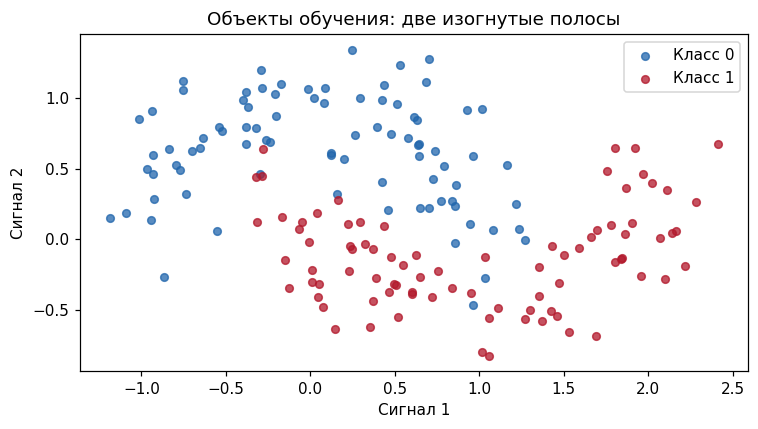

Обучение: 168 объекта; валидация: 72


In [6]:
class_values, class_labels = make_moons(n_samples=240, noise=0.23, random_state=18)
class_features = pd.DataFrame(class_values, columns=['Сигнал 1', 'Сигнал 2'])
class_target = pd.Series(class_labels, name='Класс')
X_class_train, X_class_valid, y_class_train, y_class_valid = train_test_split(
    class_features, class_target, test_size=0.3, stratify=class_target, random_state=21
)

fig, ax = plt.subplots(figsize=(7, 4))
for label, color in zip([0, 1], ['#2166ac', '#b2182b']):
    mask = y_class_train == label
    ax.scatter(
        X_class_train.loc[mask, 'Сигнал 1'], X_class_train.loc[mask, 'Сигнал 2'],
        color=color, s=25, alpha=0.75, label=f'Класс {label}',
    )
ax.set_xlabel('Сигнал 1')
ax.set_ylabel('Сигнал 2')
ax.set_title('Объекты обучения: две изогнутые полосы')
ax.legend()
fig.tight_layout()
plt.show()
print('Обучение:', len(X_class_train), 'объекта; валидация:', len(X_class_valid))

**Разбор кода и результата.**

- `make_moons(...)` создаёт две изогнутые группы с метками 0 и 1. `n_samples=240` задаёт число объектов, `noise=0.23` — разброс координат, `random_state=18` — воспроизводимость. Два результата сохраняются в массив признаков и массив меток.
- `pd.DataFrame(..., columns=[...])` именует два столбца, `pd.Series(..., name=...)` создаёт ответы. `train_test_split(...)` возвращает четыре согласованные части. `stratify=class_target` учитывает доли классов при разделении, остальные параметры имеют прежний смысл.
- `plt.subplots(...)` создаёт рисунок. `zip(...)` объединяет по позиции код класса и цвет. Цикл `for label, color in ...:` извлекает пару и выполняет строки с отступом для каждого класса. Двоеточие начинает блок; отступы определяют его границы.
- `y_class_train == label` выполняет поэлементную проверку равенства, получая логическую маску. `==` сравнивает, а `=` присваивает. `.loc[mask, 'Сигнал 1']` выбирает строки по маске и столбец по имени. Маска и таблица здесь имеют согласованные индексы.
- `scatter(...)` рисует выбранные точки. `f'Класс {label}'` — форматируемая строка: значение переменной подставляется в фигурные скобки. `set_xlabel`, `set_ylabel`, `set_title`, `legend`, `tight_layout`, `plt.show` оформляют и показывают рисунок.
- `len(...)` считает строки, `print(...)` выводит размеры: 168 объектов обучения и 72 валидации.

Изгибы групп делают задачу подходящей для демонстрации ограничений прямой границы. На пересечениях и в шумных областях даже более гибкая модель не обязана отвечать безошибочно.

Объединим приведение признаков к сопоставимому масштабу и логистическую регрессию в `Pipeline`. Масштабирование обучится только на обучающей части. Для пяти валидационных объектов посмотрим правильный класс, выбранный класс и оценки обоих классов.

In [7]:
logistic_clf = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=1.0, max_iter=1000)),
])
logistic_clf.fit(X_class_train, y_class_train)
logistic_valid_predictions = logistic_clf.predict(X_class_valid)

class_sample = X_class_valid.iloc[:5]
logistic_sample = class_sample.copy()
logistic_sample['Фактический класс'] = y_class_valid.iloc[:5]
logistic_sample['Предсказанный класс'] = logistic_clf.predict(class_sample)
probability_values = logistic_clf.predict_proba(class_sample)
logistic_class_order = logistic_clf.named_steps['model'].classes_
for column_number, label in enumerate(logistic_class_order):
    logistic_sample[f'Оценка класса {label}'] = probability_values[:, column_number]
display(logistic_sample)

,Сигнал 1,Сигнал 2,Фактический класс,Предсказанный класс,Оценка класса 0,Оценка класса 1
163,-0.794,0.821,0,0,0.978,0.022
70,2.044,-0.182,1,1,0.037,0.963
1,1.320,-0.047,1,1,0.125,0.875
222,-0.172,0.887,0,0,0.968,0.032
193,1.129,0.411,0,0,0.529,0.471


**Разбор кода и результата.**

- `Pipeline([...])` получает список пар `(имя шага, объект)`. Круглые скобки внутри списка создают кортежи. `StandardScaler()` обучает правило приведения числовых признаков к сопоставимому масштабу; исходные таблицы при этом не изменяются. Подробности масштабирования относятся к предыдущему материалу.
- `LogisticRegression(C=1.0, max_iter=1000)` создаёт классификатор. У него по умолчанию есть ограничение величины коэффициентов, называемое регуляризацией. `C` задаёт обратную силу этого ограничения: меньше `C` — сильнее ограничение. `max_iter` задаёт максимум внутренних шагов поиска параметров, а не число деревьев или число строк данных.
- `fit(...)` обучает оба шага по обучающей части. `predict(...)` возвращает классы без повторного обучения. `.iloc[:5]` выбирает первые пять строк по позиции: двоеточие означает срез от начала до позиции 5, не включая её.
- `.copy()` создаёт таблицу для результата. Добавление столбца с `y_class_valid.iloc[:5]` сохраняет соответствие по исходным индексам. `predict_proba(...)` возвращает массив оценок по классам.
- `.named_steps['model']` выбирает шаг по имени, `.classes_` читает порядок его классов. `enumerate(...)` добавляет номер столбца, начиная с нуля; цикл получает номер и код. `probability_values[:, column_number]` выбирает все строки (`:`) одного столбца. `f'Оценка класса {label}'` создаёт имя с кодом класса. `display(...)` выводит таблицу.

Уже обученный объект может возвращать и классы, и оценки. Номер столбца оценки определяется `classes_`, а не произвольной догадкой. Если у объекта оценки близки, это говорит о слабом предпочтении модели; правильность ответа всё равно проверяется по факту.

Посмотрим на коэффициенты логистической регрессии. Здесь они относятся к масштабированным сигналам, которые выходят из первого шага `Pipeline`. Поэтому не будем интерпретировать их как изменение вероятности на одну исходную единицу сигнала.

In [8]:
logistic_model = logistic_clf.named_steps['model']
display(pd.DataFrame({
    'Масштабированный признак': X_class_train.columns,
    'Коэффициент для класса 1': logistic_model.coef_[0],
}))
print('Свободный член:', round(logistic_model.intercept_[0], 3))
print('Выполнено внутренних шагов:', logistic_model.n_iter_[0])

,Масштабированный признак,Коэффициент для класса 1
0,Сигнал 1,0.901
1,Сигнал 2,-2.122


Свободный член: -0.086
Выполнено внутренних шагов: 8


**Разбор кода и результата.**

- `.named_steps['model']` извлекает обученный классификатор. `.coef_` содержит коэффициенты; `[0]` выбирает единственную строку коэффициентов бинарной модели. При порядке классов `[0, 1]` они описывают направление предпочтения класса 1.
- `X_class_train.columns` содержит имена признаков в исходном порядке. `pd.DataFrame(...)` ставит рядом имя и соответствующий коэффициент; `display(...)` показывает таблицу.
- `.intercept_[0]` — свободный член модели, `.n_iter_[0]` — фактически использованное число внутренних шагов обучения. `round(..., 3)` округляет вывод, `print(...)` печатает значения.

Положительный коэффициент при неизменных остальных признаках повышает предпочтение класса 1, отрицательный — понижает. Сам коэффициент не является вероятностью и может выходить за пределы 0–1. После преобразования в оценку классов одинаковое изменение сигнала не обязано давать одинаковую добавку к вероятности.

Количество шагов описывает работу поиска параметров; оно не является метрикой качества. Если библиотека сообщает, что обучение не сошлось, такое сообщение нужно разбирать, а не скрывать. В выполненных примерах предупреждений о сходимости нет.

В примере коэффициент первого масштабированного сигнала около 0,901, второго — около −2,122. Это разные направления предпочтения класса 1. Использовано восемь внутренних шагов; число не означает, что модель имеет восемь уровней или восемь составных моделей.

## 4. Деревья решений: последовательность вопросов

### Узлы, ветви и листья

Дерево начинает с **корневого узла**. Во внутреннем узле проверяется условие о признаке, например не превышает ли сигнал определённое значение. Ответ выбирает ветвь. В следующем узле задаётся следующий вопрос, пока объект не достигнет **листа** — конечного участка с ответом.

Во время обучения дерево подбирает признак и границу разделения так, чтобы получившиеся части были полезны для предсказания. В классификации листья содержат сведения о классах попавших туда обучающих объектов. В регрессии с используемыми стандартными настройками лист выдаёт средний числовой ответ своей обучающей группы.

Путь одного объекта можно прочитать как последовательность правил. При этом глубокое дерево становится громоздким и чувствительным к отдельным примерам. `max_depth` ограничивает длину пути, `min_samples_leaf` — минимальное число обучающих объектов в листе. Подробный разбор переобучения уже был в предыдущем файле.

Дерево не требует сопоставимого масштаба числовых признаков ради измерения расстояний: оно задаёт отдельные вопросы о столбцах. Для наших полностью числовых таблиц отдельное масштабирование перед деревом не добавляем. Это не отменяет проверки качества данных и подготовки категориальных полей в других задачах.

Обучим небольшое дерево-классификатор глубиной не больше двух. Ограничение выбрано, чтобы все его вопросы можно было прочитать на одном рисунке. Качество оценим на тех же валидационных строках, которые использовались для логистической регрессии.

In [9]:
tree_clf = DecisionTreeClassifier(max_depth=2, min_samples_leaf=8, random_state=42)
tree_clf.fit(X_class_train, y_class_train)
tree_valid_predictions = tree_clf.predict(X_class_valid)

print('Глубина обученного дерева:', tree_clf.get_depth())
print('Количество листьев:', tree_clf.get_n_leaves())
print('F1 на валидации:', round(f1_score(y_class_valid, tree_valid_predictions, zero_division=0), 3))

Глубина обученного дерева: 2
Количество листьев: 4
F1 на валидации: 0.904


**Разбор кода и результата.**

- `DecisionTreeClassifier(...)` создаёт классификатор. `max_depth=2` разрешает не более двух переходов от корня к листу; `min_samples_leaf=8` требует минимум восемь обучающих объектов в листе. `random_state=42` закрепляет случайные решения при обучении.
- `fit(...)` подбирает вопросы и ответы листьев на обучающих строках. `predict(...)` проводит каждый новый объект по получившимся ветвям и возвращает класс.
- `get_depth()` сообщает фактическую глубину, `get_n_leaves()` — число листьев. Реальное дерево может оказаться меньше заданного максимума.
- `f1_score(..., zero_division=0)` вычисляет знакомую F1 класса 1; параметр задаёт значение для неопределённого случая. `round(..., 3)` округляет число, `print(...)` печатает результаты.

Небольшое число вопросов делает модель читаемой. Это не означает, что двух уровней достаточно для любой задачи: ограничение здесь помогает рассмотреть устройство алгоритма.

Изобразим обученное дерево целиком. В узлах будут видны условие, число обучающих объектов, распределение классов и выбранный ответ. Показатель внутренней неоднородности уберём: для понимания маршрута объекта он не нужен.

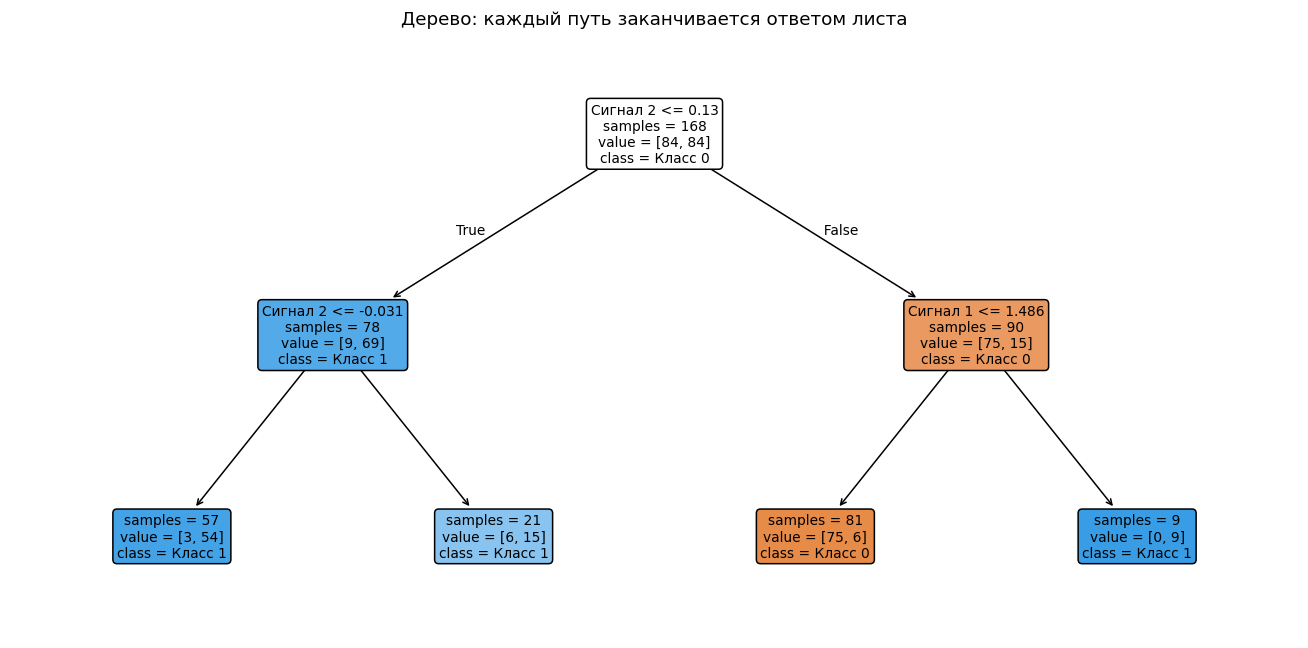

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(
    tree_clf,
    feature_names=list(X_class_train.columns),
    class_names=['Класс 0', 'Класс 1'],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9,
    ax=ax,
)
ax.set_title('Дерево: каждый путь заканчивается ответом листа')
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `plt.subplots(...)` создаёт рисунок. `plot_tree(...)` получает обученный объект и рисует его структуру; эта функция ничего не обучает. `feature_names` подписывает вопросы именами столбцов. `list(...)` превращает набор имён Pandas в обычный список.
- `class_names` задаёт названия классов в порядке 0, 1. `filled=True` включает окраску по составу классов, `rounded=True` — скругление рамок. `True` означает логическое «да», `False` — «нет»; `impurity=False` убирает дополнительный показатель из подписей. `fontsize=9` задаёт размер шрифта, `ax` — область рисунка.
- `set_title(...)` задаёт заголовок, `tight_layout()` размещает узлы, `plt.show()` выводит рисунок. Возвращаемые `plot_tree` графические объекты отдельно не сохраняем: рисунок уже находится в `fig`.

Чтение идёт сверху вниз. Условие вида `Сигнал 2 <= ...` отправляет объект влево при истинном ответе, вправо — при ложном. У листа условия нет. `samples` — число обучающих строк в узле, `value` — числа объектов классов 0 и 1 для этого дерева без весов, `class` — выбираемый класс. Эти значения описывают обучение, а не результаты валидации. Узлы разных уровней содержат вложенные группы: суммировать все `samples` на рисунке как разные объекты нельзя.

На сохранённой схеме первый вопрос проверяет, не превышает ли «Сигнал 2» примерно 0,13. Ветка True означает «условие верно», False — «неверно». В корне находятся 168 обучающих объектов с составом [84, 84]. При равных количествах выбирается первый класс в порядке классов, здесь 0. Это подпись текущего узла: окончательный ответ конкретного объекта берётся из достигнутого листа. Например, крайний левый лист содержит 57 строк, из них 54 класса 1, и выдаёт класс 1.

Теперь применим ту же идею вопросов к прогнозу длительности. Создадим регрессор и получим ответы для тех же новых заявок, что у линейной модели. Сравнение покажет характерное свойство обычного дерева: одинаковый ответ для объектов, попавших в один лист.

In [11]:
tree_reg = DecisionTreeRegressor(max_depth=3, min_samples_leaf=4, random_state=42)
tree_reg.fit(X_reg_train, y_reg_train)
tree_reg_new = new_requests.copy()
tree_reg_new['Прогноз дерева, минуты'] = tree_reg.predict(new_requests)
display(tree_reg_new)
print('Листья для новых строк:', tree_reg.apply(new_requests))

,Позиций в заявке,"Прогноз дерева, минуты"
0,10,19.592
1,25,52.141
2,50,71.726


Листья для новых строк: [ 4 10 14]


**Разбор кода и результата.**

- `DecisionTreeRegressor(...)` создаёт числовую модель с ограничением глубины 3 и минимумом четырёх обучающих объектов в листе. `random_state` закрепляет воспроизводимость.
- `fit(...)` учит дерево по тем же `X_reg_train`, `y_reg_train`. `.copy()` создаёт отдельную таблицу новых заявок, `predict(...)` добавляет числовые ответы. `display(...)` выводит их.
- `apply(new_requests)` возвращает для каждой строки внутренний номер достигнутого листа. `print(...)` показывает эти номера. Номера — технические идентификаторы узлов, а не классы и не порядок качества.

В стандартном регрессионном дереве ответ листа — средняя длительность обучающих объектов этого листа. За пределами диапазона признака дерево продолжает направлять строки в крайний подходящий лист. Оно не продолжает наклон прямой, как линейная регрессия. Ни такое постоянство, ни линейное продолжение сами по себе не гарантируют верного ответа в новом диапазоне.

## 5. Случайный лес: объединение разнообразных деревьев

### От одного дерева к ансамблю

**Ансамбль** — модель, объединяющая несколько моделей. В случайном лесе каждое дерево обучается на своей случайной подборке строк с повторениями: одна исходная строка может попасть несколько раз, другая не попасть вовсе. Дополнительно при выборе разделений можно рассматривать случайную часть признаков. Это помогает деревьям отличаться друг от друга.

Деревья леса не строят последовательные поправки к общему ответу: их можно обучать независимо. Объединение разнообразных ответов обычно уменьшает чувствительность к отдельному обучающему набору по сравнению с одним гибким деревом, но не гарантирует улучшение в каждой задаче.

В регрессии `RandomForestRegressor` усредняет числовые прогнозы деревьев. В классификации `RandomForestClassifier` в scikit-learn усредняет **оценки классов**, затем выбирает класс с наибольшей средней оценкой. Поэтому точное правило не следует описывать как обязательное большинство уже готовых меток деревьев: усреднение оценок и голосование метками могут дать разные ответы.

У леса сложнее проследить единую короткую цепочку объяснения, чем у маленького дерева. Он также хранит много деревьев и требует больше памяти. Здесь ограничимся 80 небольшими деревьями.

Обучим лес-классификатор на тех же двух сигналах. Явно включим случайную выборку строк с повторениями и выбор части признаков в узле. Сохраним предсказания для общего сравнения, не меняя ранее заданную валидационную часть.

In [12]:
forest_clf = RandomForestClassifier(
    n_estimators=80,
    max_depth=5,
    min_samples_leaf=3,
    max_features='sqrt',
    bootstrap=True,
    random_state=42,
    n_jobs=1,
)
forest_clf.fit(X_class_train, y_class_train)
forest_valid_predictions = forest_clf.predict(X_class_valid)
print('Деревьев в лесу:', len(forest_clf.estimators_))
print('F1 на валидации:', round(f1_score(y_class_valid, forest_valid_predictions, zero_division=0), 3))

Деревьев в лесу: 80
F1 на валидации: 0.93


**Разбор кода и результата.**

- `RandomForestClassifier(...)` создаёт лес. `n_estimators=80` задаёт число деревьев; `max_depth=5` и `min_samples_leaf=3` ограничивают каждое дерево. Эти ограничения относятся к составным моделям, а не к единому большому дереву.
- `max_features='sqrt'` включает библиотечное правило выбора количества признаков-кандидатов для разделения. В нашем случае с двумя признаками рассматривается один признак-кандидат в узле. `bootstrap=True` включает выбор строк с повторениями; `random_state=42` делает случайность воспроизводимой.
- `n_jobs=1` задаёт последовательное выполнение. Лес допускает параллельное обучение деревьев, но для маленького примера оно не требуется.
- `fit(...)` обучает ансамбль, `predict(...)` получает готовые классы. `.estimators_` — список обученных деревьев; `len(...)` считает их. `f1_score(..., zero_division=0)`, `round(..., 3)` и `print(...)` вычисляют и выводят знакомую оценку.

Большее число деревьев не означает автоматически большую глубину каждого из них. Увеличение числа деревьев часто стабилизирует усреднение, но расходует больше ресурсов и не исправляет неподходящие признаки. Ограничение сложности отдельных деревьев остаётся отдельным решением.

Создадим лес для числового прогноза. В нашем регрессионном наборе только один признак, поэтому разнообразие деревьев возникает прежде всего из разных подборок обучающих строк. Снова используем общую обучающую часть и прежние три новых заявки.

In [13]:
forest_reg = RandomForestRegressor(
    n_estimators=80,
    max_depth=5,
    min_samples_leaf=2,
    bootstrap=True,
    random_state=42,
    n_jobs=1,
)
forest_reg.fit(X_reg_train, y_reg_train)
forest_reg_new = new_requests.copy()
forest_reg_new['Прогноз леса, минуты'] = forest_reg.predict(new_requests)
display(forest_reg_new)

,Позиций в заявке,"Прогноз леса, минуты"
0,10,20.268
1,25,49.589
2,50,72.412


**Разбор кода и результата.**

- `RandomForestRegressor(...)` создаёт числовой вариант леса. `n_estimators` задаёт 80 деревьев, `max_depth` и `min_samples_leaf` — ограничения каждого дерева. `bootstrap=True` сохраняет выбор строк с повторениями, `random_state` — воспроизводимость, `n_jobs=1` — последовательный запуск.
- `fit(...)` обучает лес по числовым ответам. `.copy()` создаёт таблицу для вывода, `predict(...)` возвращает усреднённый прогноз ансамбля для новых объектов. `display(...)` показывает таблицу.

Каждое дерево имеет свои границы листьев и ответы. Их среднее может дать более плавную последовательность прогнозов, чем одно дерево, но всё ещё не означает линейного продолжения тренда за пределами обучающих значений.

Для заявки из 25 позиций сравним прогнозы первых пяти деревьев с усреднением всех 80. Первые пять нужны только для чтения таблицы; итоговый лес использует весь ансамбль. Проверим, что рассчитанное среднее совпадает с обычным вызовом `predict`.

In [14]:
one_request = new_requests.iloc[[1]]
tree_answers = np.array([
    fitted_tree.predict(one_request.to_numpy())[0]
    for fitted_tree in forest_reg.estimators_
])
forest_answer = forest_reg.predict(one_request)[0]
assert np.isclose(tree_answers.mean(), forest_answer)

forest_average_table = pd.DataFrame({
    'Источник': [f'Дерево {number}' for number in range(1, 6)] + [
        'Среднее всех 80 деревьев', 'predict случайного леса'
    ],
    'Прогноз, минуты': list(tree_answers[:5]) + [tree_answers.mean(), forest_answer],
})
display(forest_average_table)

,Источник,"Прогноз, минуты"
0,Дерево 1,51.723
1,Дерево 2,50.391
2,Дерево 3,51.065
3,Дерево 4,51.021
4,Дерево 5,51.138
5,Среднее всех 80 деревьев,49.589
6,predict случайного леса,49.589


**Разбор кода и результата.**

- `.iloc[[1]]` выбирает вторую строку по позиции и сохраняет двумерную таблицу: внутренние скобки создают список из одной позиции. `.iloc[1]` без списка вернул бы одномерный объект `Series`, что не подходит для входа модели в этом примере.
- `[... for fitted_tree in forest_reg.estimators_]` — списковое включение: короткая запись цикла, создающего список ответов всех деревьев. `one_request.to_numpy()` передаёт отдельному внутреннему дереву массив без имён столбцов: внутренние деревья леса обучались именно на таких массивах. `predict(...)[0]` берёт единственный ответ. `np.array(...)` превращает список в массив.
- `forest_reg.predict(one_request)[0]` получает ответ всего леса через обычный интерфейс с именованной таблицей. `tree_answers.mean()` находит среднее ответов деревьев. `np.isclose(...)` проверяет совпадение чисел с учётом небольших вычислительных погрешностей, `assert` останавливает выполнение, если проверка ложна.
- `range(1, 6)` создаёт номера 1–5; `f'Дерево {number}'` подставляет номер в строку. `+` соединяет списки названий. `[:5]` выбирает первые пять ответов, `list(...)` переводит их в список; следующий `+` добавляет два итоговых числа. `pd.DataFrame(...)` и `display(...)` показывают результат.

Отдельные деревья могут отвечать по-разному, а две итоговые строки совпадают. Это усреднение **готовых числовых прогнозов**. В прикладном коде повторять внутреннее вычисление не нужно: `predict` уже делает это сам.

Выполненный лес для этой заявки выдаёт около 49,589 минуты. Первые пять показанных деревьев отвечают примерно от 50,4 до 51,7 минуты, но итог вычислен по всем 80 деревьям, включая остальные. Поэтому среднее только первых пяти строк не должно совпасть с итоговой строкой.

## 6. Градиентный бустинг: последовательные поправки

### Чем он отличается от случайного леса

В бустинге следующая небольшая модель строится с учётом того, что уже предсказывает весь текущий ансамбль. Она учится давать полезную **поправку**, а общий ответ постепенно обновляется. Поэтому следующие этапы зависят от предыдущих.

В нашем регрессионном примере со стандартным критерием исходный прогноз — постоянный ориентир по обучающим ответам. Дальнейшие деревья приближают оставшиеся отклонения от текущего прогноза. В классификации поправки строятся во внутренней шкале оценок, после чего получаются оценки классов. Это не обучение каждого нового дерева готовым меткам «ошибка/не ошибка» и не простое усреднение прогнозов независимых деревьев.

| Свойство | Случайный лес | Градиентный бустинг в примере |
|---|---|---|
| Связь деревьев при обучении | Деревья обучаются независимо друг от друга | Новый этап зависит от текущего общего ответа |
| Что объединяется | Готовые числовые ответы или оценки классов | Исходный ответ и последовательные поправки |
| Типичные настройки | Число деревьев, их сложность, случайность выборок | Число этапов, сложность дерева, величина вклада каждого этапа |

`learning_rate` задаёт вклад очередной поправки. Маленькие вклады часто требуют большего числа этапов; увеличивать только один параметр без проверки качества бессмысленно. Слишком большое число гибких поправок может подстроиться под шум. Здесь используем классические `GradientBoostingClassifier` и `GradientBoostingRegressor`; другие реализации бустинга могут иметь дополнительные возможности и настройки.

Обучим по одной модели бустинга для двух уже знакомых задач. У каждого ансамбля будет 80 этапов с небольшими деревьями глубиной не более двух и вкладом этапа 0,05. Параметры выбраны заранее для демонстрации, поиск оптимальных настроек не проводится.

In [15]:
boost_clf = GradientBoostingClassifier(
    n_estimators=80, learning_rate=0.05, max_depth=2,
    min_samples_leaf=3, random_state=42,
)
boost_reg = GradientBoostingRegressor(
    n_estimators=80, learning_rate=0.05, max_depth=2,
    min_samples_leaf=3, random_state=42,
)
boost_clf.fit(X_class_train, y_class_train)
boost_reg.fit(X_reg_train, y_reg_train)
boost_valid_predictions = boost_clf.predict(X_class_valid)
print('F1 классификатора на валидации:', round(f1_score(y_class_valid, boost_valid_predictions, zero_division=0), 3))
print('MAE регрессора на валидации, минуты:', round(mean_absolute_error(y_reg_valid, boost_reg.predict(X_reg_valid)), 3))

F1 классификатора на валидации: 0.93
MAE регрессора на валидации, минуты: 1.689


**Разбор кода и результата.**

- `GradientBoostingClassifier(...)` создаёт классификатор, `GradientBoostingRegressor(...)` — регрессор. Это разные объекты для разных ответов, несмотря на одинаковые значения настроек.
- `n_estimators=80` задаёт число этапов. В наших бинарном и числовом примерах на каждом этапе добавляется одно дерево. `learning_rate=0.05` уменьшает вклад каждой новой поправки; это не порог класса и не вероятность.
- `max_depth=2` и `min_samples_leaf=3` ограничивают деревья-поправки. `random_state=42` закрепляет случайные решения алгоритма. Здесь настройка относится к последовательному построению, а не к независимым деревьям леса.
- Два вызова `fit(...)` получают соответствующие задачам обучающие данные. `predict(...)` использует весь обученный ансамбль, а не только последнее дерево.
- `f1_score(..., zero_division=0)` и `mean_absolute_error(...)` оценивают валидационные ответы, `round(..., 3)` округляет вывод, `print(...)` показывает числа. Последняя строка сначала получает числовые прогнозы вложенным вызовом `boost_reg.predict(...)`, затем передаёт их в метрику.

Число 80 имеет разный смысл в двух ансамблях: у леса это 80 самостоятельно обученных деревьев, у нашего бустинга — 80 последовательных поправок. Одинаковое число составных деревьев не делает модели эквивалентными.

Прочитаем промежуточные прогнозы уже обученного регрессионного бустинга после 1, 10, 40 и 80 этапов. Каждый такой прогноз включает начальный ответ и все поправки до указанного этапа. Повторно обучать модель или выбирать настройки по этой таблице не будем.

In [16]:
stage_rows = []
for stage_number, stage_predictions in enumerate(boost_reg.staged_predict(X_reg_valid), start=1):
    if stage_number in [1, 10, 40, 80]:
        stage_rows.append({
            'После этапа': stage_number,
            'Прогноз для первой валидационной строки': stage_predictions[0],
            'MAE всей валидации, минуты': mean_absolute_error(y_reg_valid, stage_predictions),
        })

display(pd.DataFrame(stage_rows).set_index('После этапа'))
print('Факт для первой валидационной строки:', round(y_reg_valid.iloc[0], 3))

,Прогноз для первой валидационной строки,"MAE всей валидации, минуты"
После этапа,,
1,41.400,18.931
10,47.980,12.051
40,57.508,3.237
80,59.478,1.689


Факт для первой валидационной строки: 61.263


**Разбор кода и результата.**

- `stage_rows = []` создаёт пустой список. `staged_predict(...)` последовательно выдаёт прогнозы ансамбля после каждого этапа; `enumerate(..., start=1)` добавляет номер, начиная с единицы.
- Цикл `for` перебирает все этапы. `if stage_number in [1, 10, 40, 80]:` выполняет блок только при наличии номера в списке. `if` — условная конструкция, `in` здесь проверяет принадлежность. Двоеточие и отступ задают строки условного блока.
- `.append({...})` добавляет словарь строки в список. `[0]` берёт прогноз первого объекта, `mean_absolute_error(...)` считает MAE **всех** валидационных объектов. `pd.DataFrame(...)` собирает строки, `set_index('После этапа')` делает номер этапа индексом, `display(...)` выводит таблицу.
- `y_reg_valid.iloc[0]` выбирает первый фактический ответ по позиции, `round(..., 3)` округляет его, `print(...)` печатает. Важно не заменить `.iloc[0]` на `[0]`: после разбиения исходная метка индекса 0 может относиться к другой строке или отсутствовать.

Здесь видно накопление поправок к одному и тому же объекту и изменение общей ошибки. Промежуточный прогноз — не прогноз отдельного дерева. Снижение ошибки не обязано продолжаться бесконечно и не обязано быть монотонным на валидации. Для рабочего выбора числа этапов нужна схема проверки из предыдущего материала.

В сохранённом результате прогноз первой строки изменяется примерно с 41,400 до 59,478 минуты, а её фактический ответ — 61,263. Одновременно MAE всех валидационных строк снижается примерно с 18,931 после первого этапа до 1,689 после восьмидесятого. Это два разных наблюдения: движение одного прогноза и обобщённая ошибка всей части.

## 7. Сопоставление поведения обученных моделей

### Один числовой набор — разные формы прогноза

Теперь все четыре регрессора обучены на одинаковых строках. Сравним их валидационные ответы, а затем форму прогноза на общей сетке. Никаких дополнительных обучений здесь не будет. Скачок в учебных длительностях специально делает прямую менее подходящей на части диапазона; на других данных соотношение результатов может измениться.

Соберём модели в словарь и для каждой посчитаем MAE на одной валидации. Рядом покажем прогноз для заявки из 50 позиций, которая выходит за пределы обучения. Валидационная ошибка и ответ на такую заявку — разные сведения: правильная длительность для 50 позиций неизвестна.

In [17]:
reg_models = {
    'Линейная регрессия': linear_reg,
    'Дерево': tree_reg,
    'Случайный лес': forest_reg,
    'Градиентный бустинг': boost_reg,
}
reg_comparison_rows = []
outside_request = pd.DataFrame({'Позиций в заявке': [50]})
for name, model in reg_models.items():
    reg_comparison_rows.append({
        'Модель': name,
        'MAE валидации, минуты': mean_absolute_error(y_reg_valid, model.predict(X_reg_valid)),
        'Прогноз при 50 позициях, минуты': model.predict(outside_request)[0],
    })
display(pd.DataFrame(reg_comparison_rows).set_index('Модель'))

,"MAE валидации, минуты","Прогноз при 50 позициях, минуты"
Модель,,
Линейная регрессия,3.151,90.636
Дерево,2.391,71.726
Случайный лес,1.567,72.412
Градиентный бустинг,1.689,70.973


**Разбор кода и результата.**

- `reg_models` — словарь, связывающий название с **уже обученным объектом**. Создание словаря не копирует и не обучает модели. `reg_comparison_rows = []` создаёт список для результатов.
- `pd.DataFrame(...)` создаёт один новый объект с прежней схемой признаков. `.items()` возвращает пары «название, объект», которые цикл `for name, model in ...` распределяет по двум переменным.
- `model.predict(X_reg_valid)` получает ответы для общих проверочных строк; `mean_absolute_error(...)` сравнивает их с фактами. `model.predict(outside_request)[0]` получает единственный ответ для 50 позиций.
- `.append({...})` накапливает строки, `pd.DataFrame(...)` превращает их в таблицу, `.set_index('Модель')` задаёт имена строк, `display(...)` выводит результат.

Сравнение относится к этой валидации при этих заранее заданных настройках. Хорошая MAE внутри наблюдавшегося диапазона не подтверждает качество экстраполяции. В частности, одинаковые ответы разных деревьев за границей могут отражать устройство их правил, а не правильный прогноз процесса.

Построим четыре линии до 50 позиций. Заштрихованная область начнётся за максимальным размером обучающей заявки. Точки отображают только имеющиеся факты, а линии справа от них — продолжение правил моделей без известных новых ответов.

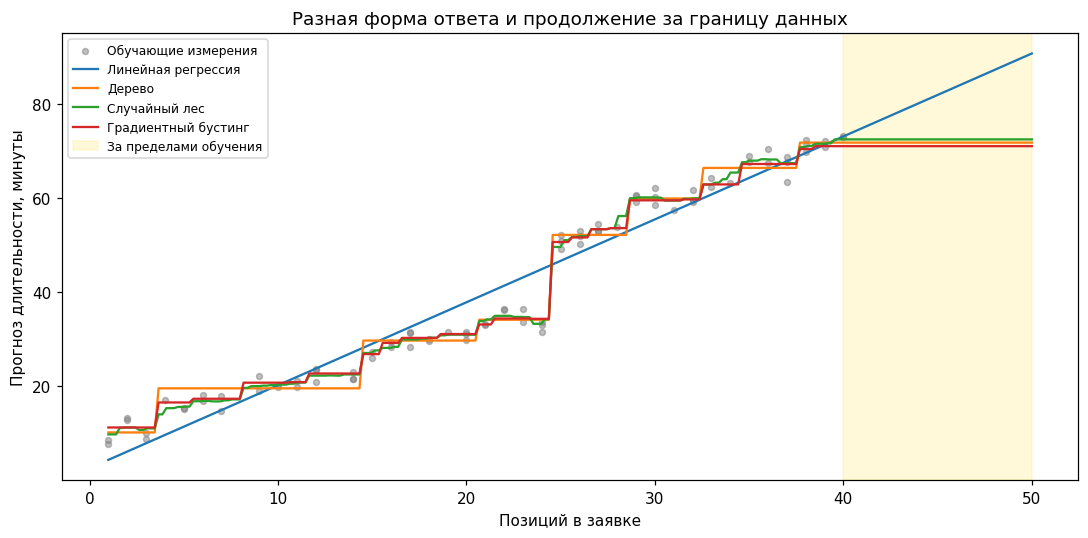

In [18]:
wide_reg_grid = pd.DataFrame({'Позиций в заявке': np.linspace(1, 50, 240)})
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_reg_train['Позиций в заявке'], y_reg_train, color='grey', s=15, alpha=0.5, label='Обучающие измерения')
for name, model in reg_models.items():
    ax.plot(wide_reg_grid['Позиций в заявке'], model.predict(wide_reg_grid), label=name)
ax.axvspan(X_reg_train['Позиций в заявке'].max(), 50, color='gold', alpha=0.15, label='За пределами обучения')
ax.set_xlabel('Позиций в заявке')
ax.set_ylabel('Прогноз длительности, минуты')
ax.set_title('Разная форма ответа и продолжение за границу данных')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `np.linspace(...)` задаёт более широкий диапазон, `pd.DataFrame(...)` сохраняет схему входа. `plt.subplots(...)` создаёт рисунок, `scatter(...)` показывает обучающие измерения.
- Цикл по `reg_models.items()` получает название и объект. `predict(...)` вычисляет линии, `plot(..., label=name)` добавляет их с подписями. Модель при этом не меняется.
- `.max()` находит наибольший размер среди обучающих строк. `axvspan(...)` выделяет вертикальную полосу от этой границы до 50; `color` и `alpha` задают цвет и прозрачность.
- `set_xlabel`, `set_ylabel`, `set_title` задают подписи; `legend(fontsize=8)` показывает компактную легенду, `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Линейная регрессия продолжает прямую. Дерево даёт ступени; лес объединяет много ступенчатых ответов; бустинг последовательно складывает поправки небольших деревьев. В этом одномерном примере за всеми обученными порогами деревья перестают менять лист, поэтому их конечные ансамбли выходят на постоянные участки.

Усреднение леса остаётся в пределах ответов его деревьев. Бустинг использует поправки, поэтому его числовой ответ в общем случае может выйти за диапазон обучающих ответов. Это не делает его способным правильно продолжить любой тренд за диапазоном признаков.

### Один набор классов — разные границы

В классификации сопоставим логистическую регрессию, небольшое дерево, лес и бустинг. Граница показывает, какой класс модель выберет в каждой точке пространства двух сигналов. Такие рисунки возможны без дополнительных условностей именно потому, что в примере всего два признака.

Соберём показатели четырёх классификаторов на одной валидационной части. Здесь не выбираем победителя для внедрения и не меняем настройки после просмотра таблицы: нам важно связать результат с формой границ на следующем рисунке.

In [19]:
class_models = {
    'Логистическая регрессия': logistic_clf,
    'Дерево глубиной 2': tree_clf,
    'Случайный лес': forest_clf,
    'Градиентный бустинг': boost_clf,
}
class_comparison_rows = []
for name, model in class_models.items():
    predicted = model.predict(X_class_valid)
    class_comparison_rows.append({
        'Модель': name,
        'Accuracy валидации': accuracy_score(y_class_valid, predicted),
        'F1 класса 1 на валидации': f1_score(y_class_valid, predicted, zero_division=0),
    })
display(pd.DataFrame(class_comparison_rows).set_index('Модель'))

,Accuracy валидации,F1 класса 1 на валидации
Модель,,
Логистическая регрессия,0.875,0.873
Дерево глубиной 2,0.903,0.904
Случайный лес,0.931,0.930
Градиентный бустинг,0.931,0.930


**Разбор кода и результата.**

- `class_models` хранит названия и обученные объекты. Переменная `model` в цикле каждый раз ссылается на очередной объект из `.items()`.
- `predict(...)` получает классы на общих валидационных строках. `accuracy_score(...)` и `f1_score(..., zero_division=0)` используют правильные ответы и эти предсказания. Формулы и свойства показателей разобраны в предыдущем файле.
- `class_comparison_rows = []` создаёт список, `.append({...})` добавляет строки. `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют и показывают таблицу.

Результат ограничен конкретным набором и настройками. Например, дерево специально сделали маленьким ради читаемой схемы, а для других моделей не проводили подбор. Поэтому таблица не устанавливает, что одна семья алгоритмов всегда сильнее другой.

В нашем выполнении F1 логистической регрессии около 0,873, небольшого дерева — 0,904, леса и бустинга — 0,930. Совпадение итоговой F1 у двух ансамблей не означает одинаковых правил во всём пространстве признаков: их границы на следующем рисунке различаются.

Подготовим общую сетку точек для рисунков и функцию, которая закрашивает области предсказанных классов. Сетка покрывает диапазон обучающих сигналов с небольшим полем вокруг. Она содержит только координаты, без правильных классов, и нужна для визуализации уже обученных правил.

In [20]:
signal_1_axis = np.linspace(X_class_train['Сигнал 1'].min() - 0.3, X_class_train['Сигнал 1'].max() + 0.3, 100)
signal_2_axis = np.linspace(X_class_train['Сигнал 2'].min() - 0.3, X_class_train['Сигнал 2'].max() + 0.3, 100)
grid_x, grid_y = np.meshgrid(signal_1_axis, signal_2_axis)
class_grid = pd.DataFrame({'Сигнал 1': grid_x.ravel(), 'Сигнал 2': grid_y.ravel()})

def draw_class_regions(model, ax, title):
    regions = model.predict(class_grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, regions, levels=[-0.5, 0.5, 1.5], colors=['#dceaf7', '#f9dedb'])
    for label, color in zip([0, 1], ['#2166ac', '#b2182b']):
        mask = y_class_train == label
        ax.scatter(
            X_class_train.loc[mask, 'Сигнал 1'], X_class_train.loc[mask, 'Сигнал 2'],
            color=color, s=13, alpha=0.7, label=f'Класс {label}: обучение',
        )
    ax.set_title(title)
    ax.set_xlabel('Сигнал 1')
    ax.set_ylabel('Сигнал 2')
    ax.set_xlim(grid_x.min(), grid_x.max())
    ax.set_ylim(grid_y.min(), grid_y.max())

print('Точек сетки для визуализации:', len(class_grid))

Точек сетки для визуализации: 10000


**Разбор кода.**

- `.min()` и `.max()` находят крайние значения обучающего столбца; `- 0.3` и `+ 0.3` добавляют поле рисунка. `np.linspace(..., 100)` создаёт 100 координат по каждой оси.
- `np.meshgrid(...)` превращает два списка координат в две согласованные двумерные сетки. `.ravel()` разворачивает каждую сетку в последовательность, `pd.DataFrame(...)` делает из пар координат 10 000 строк с прежними именами признаков. `len(...)` и `print(...)` сообщают их количество.
- `def draw_class_regions(model, ax, title):` определяет функцию с тремя параметрами. Её тело с отступом пока не выполняется; оно сработает при вызове. `class_grid`, `grid_x`, `grid_y` и обучающие данные берутся из переменных, определённых выше. Функция рисует в переданной области, отдельное значение через `return` не возвращает.
- `predict(...)` получает классы сетки, `.reshape(grid_x.shape)` возвращает им двумерную форму. `.shape` — атрибут с размерностями. `contourf(...)` закрашивает области по значениям; `levels` задаёт границы цветовых интервалов вокруг классов 0 и 1, `colors` — цвета фона.
- `zip(...)`, цикл `for`, сравнение `==` и `.loc[...]` выбирают обучающие точки каждого класса. `scatter(...)` рисует их поверх фона; `f'...'` подставляет код в подпись.
- `set_title`, `set_xlabel`, `set_ylabel` задают подписи; `set_xlim` и `set_ylim` закрепляют одинаковые пределы осей по сетке. Это подготовка одинаковых рисунков, а не новая модель.

Применим подготовленную функцию к четырём обученным классификаторам. На всех панелях одинаковые координаты и точки. Фон показывает предсказанный класс, а цвет точки — известный обучающий класс; несовпадение на рисунке относится к обучающему объекту, не к валидационной метрике.

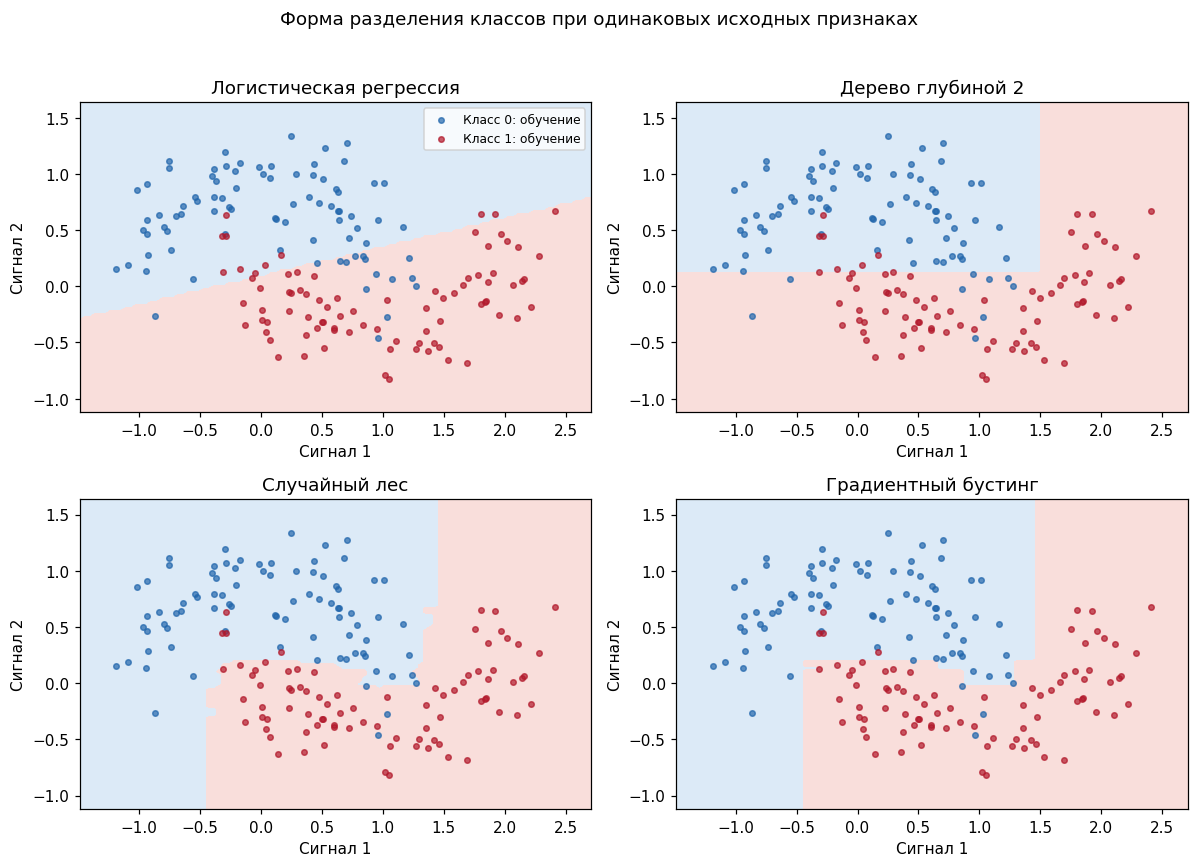

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (name, model) in zip(axes.flat, class_models.items()):
    draw_class_regions(model, ax, name)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Форма разделения классов при одинаковых исходных признаках')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Разбор кода и результата.**

- `plt.subplots(2, 2, ...)` создаёт четыре области в двух рядах. `axes.flat` последовательно перебирает их без вложенного цикла. `class_models.items()` выдаёт пары названий и моделей; `zip(...)` сопоставляет область и пару.
- Запись `for ax, (name, model) in ...` распаковывает вложенные элементы. `draw_class_regions(model, ax, name)` вызывает определённую выше функцию с выбранной моделью, областью и заголовком.
- `axes[0, 0]` выбирает верхний левый график; `legend(fontsize=8)` добавляет легенду там. `fig.suptitle(...)` задаёт общий заголовок. `tight_layout(rect=(0, 0, 1, 0.96))` размещает панели и оставляет место сверху. `plt.show()` выводит рисунок.

Логистическая регрессия делит плоскость прямой. Одно небольшое дерево создаёт несколько областей с границами вдоль осей сигналов. Лес и бустинг объединяют много таких разбиений и могут приближать более сложные формы. Зубчатая или очень подробная граница сама по себе не доказывает высокое качество на новых объектах; для этого нужны проверочные ответы.

## 8. K-Means: группы вокруг центров

### Что происходит при обучении

Теперь уберём правильные ответы: есть только признаки объектов, а готового списка классов нет. K-Means получает заданное число групп `k` и ищет для них центры.

Обучение повторяет два основных действия: относит каждый объект к ближайшему текущему центру и сдвигает центр к среднему расположению объектов своей группы. Перед этим выбираются начальные центры. Остановка происходит, когда изменения становятся достаточно малы или исчерпан предел шагов. Найденное решение может зависеть от начального выбора, поэтому полезно несколько запусков.

Это не поиск заранее известных типов клиентов и не автоматическое открытие «правильного» числа групп. Номер кластера — техническая метка. Чтобы дать группе содержательное описание, нужно изучить её признаки и контекст. Идея обучения без учителя уже обсуждалась ранее; здесь важны конкретные свойства K-Means.

Алгоритм ориентируется на расстояния, поэтому масштаб признаков влияет на результат. Он лучше подходит для компактных групп вокруг центров, чем для изогнутых полос или групп со сложной формой. Сильные выбросы могут сдвигать центры. Для примера возьмём условную частоту покупок и средний чек, приведя их к сопоставимому масштабу внутри `Pipeline`.

Создадим 120 условных клиентских профилей. Генератор сформирует три компактных облака, но их исходные метки использовать не будем: K-Means получит только два признака. Частота — условная средняя оценка за месяц, поэтому у неё могут быть дробные значения.

In [22]:
client_values, _ = make_blobs(
    n_samples=[40, 45, 35],
    centers=[[3, 25], [10, 70], [16, 30]],
    cluster_std=[1.0, 1.6, 1.1],
    random_state=32,
)
client_features = pd.DataFrame({
    'Частота покупок, в месяц': client_values[:, 0],
    'Средний чек, руб.': client_values[:, 1] * 100,
})
display(client_features.head())
print('Объектов для группировки:', len(client_features))

,"Частота покупок, в месяц","Средний чек, руб."
0,8.348,7136.455
1,16.430,2957.183
2,8.631,7210.022
3,3.053,2528.971
4,16.497,3070.720


Объектов для группировки: 120


**Разбор кода и результата.**

- `make_blobs(...)` создаёт облака точек. `n_samples=[40, 45, 35]` задаёт число объектов в каждом облаке, `centers` — исходные положения центров генератора, `cluster_std` — разбросы, `random_state` — воспроизводимость. Эти центры нужны генератору, а не передаются в обучение K-Means.
- Функция возвращает координаты и исходные метки. `client_values, _ = ...` распределяет два результата. `_` — обычное имя переменной; по соглашению так обозначают результат, который далее не используется. Это не передача меток модели и не специальная операция удаления.
- `client_values[:, 0]` и `[:, 1]` выбирают все строки первого и второго столбцов. `* 100` меняет единицу отображения второго признака на рубли в нашей имитации. `pd.DataFrame({...})` собирает именованные признаки.
- `head()` выбирает первые пять строк, `display(...)` показывает их. `len(...)` считает профили, `print(...)` выводит число.

Разные величины признаков не означают, что средний чек должен полностью определять близость объектов. Следующая последовательность обучит масштабирование на этих профилях. В демонстрации исследуется структура имеющихся объектов, а не проводится независимая проверка качества кластеризации будущих данных.

Зададим три кластера и десять запусков с разными начальными центрами. Это разные настройки: три — число итоговых групп, десять — число попыток найти хорошее расположение центров. После обучения вернём найденные центры в исходные единицы и покажем размер каждой группы.

In [23]:
cluster_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('cluster', KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)),
])
cluster_labels = cluster_pipeline.fit_predict(client_features)
cluster_model = cluster_pipeline.named_steps['cluster']
original_centers = cluster_pipeline.named_steps['scale'].inverse_transform(cluster_model.cluster_centers_)

cluster_centers = pd.DataFrame(original_centers, columns=client_features.columns)
cluster_centers.index.name = 'Кластер'
cluster_centers['Объектов'] = pd.Series(cluster_labels).value_counts().sort_index()
display(cluster_centers)
print('Шагов в выбранном запуске:', cluster_model.n_iter_)

,"Частота покупок, в месяц","Средний чек, руб.",Объектов
Кластер,,,
0,3.141,2496.440,40
1,10.296,7019.323,45
2,16.316,3009.087,35


Шагов в выбранном запуске: 2


**Разбор кода и результата.**

- `Pipeline(...)` объединяет `StandardScaler()` и `KMeans(...)`. Число `n_clusters=3` задаём мы; алгоритм не выводит его из таблицы автоматически. `init='k-means++'` использует начальный выбор разнесённых центров с учётом данных. `n_init=10` запускает поиск десять раз и оставляет вариант с лучшим внутренним критерием. `random_state=42` делает начальные выборы воспроизводимыми.
- `fit_predict(client_features)` обучает последовательность и сразу возвращает номера кластеров обучающих строк. Правильные ответы в вызов не передаются. Это отличается от `predict` после обучения, который только назначает группы новым строкам.
- `.named_steps[...]` выбирает нужный шаг по имени. `.cluster_centers_` содержит центры **в масштабированных координатах**. `inverse_transform(...)` у обученного масштабирования переводит их обратно в исходные единицы для человека; эта операция не переобучает подготовку.
- `pd.DataFrame(..., columns=...)` создаёт таблицу центров. `.index.name = 'Кластер'` подписывает индекс строк. `pd.Series(cluster_labels).value_counts()` считает объекты каждого номера, `.sort_index()` упорядочивает по номеру. Присваивание нового столбца соединяет размеры с соответствующими индексами центров. `display(...)` выводит таблицу.
- `.n_iter_` — число шагов в выбранном лучшем запуске, а не число всех попыток и не количество кластеров. `print(...)` показывает его.

Центр — средний профиль группы; такой профиль не обязан совпадать с реальным объектом. Кластер 0 не «лучше» кластера 1, и между запусками номера могут переставляться. Для сравнения решений важны состав и расположение групп, а не совпадение цифровых имён.

В этом выполнении получились группы из 40, 45 и 35 объектов. Кластер 0 имеет центр примерно «3,14 покупки и чек 2496 руб.», кластер 1 — «10,30 и 7019 руб.», кластер 2 — «16,32 и 3009 руб.». Эти описания читаются по найденным центрам и относятся к текущей нумерации, а не к постоянным названиям клиентских типов.

Покажем найденные группы цветом, а центры — чёрными крестами. Оси оставим в исходных единицах для чтения профилей. Сама близость при обучении определялась после масштабирования, поэтому геометрические расстояния на этом рисунке с разными единицами осей не следует буквально принимать за использованные моделью расстояния.

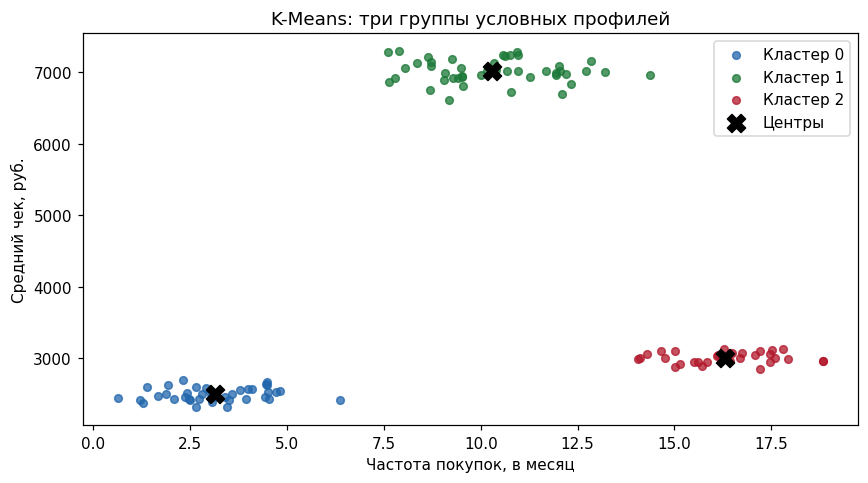

In [24]:
cluster_colors = ['#2166ac', '#1b7837', '#b2182b']
fig, ax = plt.subplots(figsize=(8, 4.5))
for cluster_number, color in zip(range(3), cluster_colors):
    mask = cluster_labels == cluster_number
    ax.scatter(
        client_features.loc[mask, 'Частота покупок, в месяц'],
        client_features.loc[mask, 'Средний чек, руб.'],
        color=color, s=25, alpha=0.75, label=f'Кластер {cluster_number}',
    )
ax.scatter(
    cluster_centers['Частота покупок, в месяц'], cluster_centers['Средний чек, руб.'],
    color='black', marker='X', s=140, label='Центры',
)
ax.set_xlabel('Частота покупок, в месяц')
ax.set_ylabel('Средний чек, руб.')
ax.set_title('K-Means: три группы условных профилей')
ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `cluster_colors` — список трёх цветов. `range(3)` даёт номера 0, 1, 2; `zip(...)` соединяет номер с цветом. `plt.subplots(...)` создаёт рисунок и область.
- В цикле `cluster_labels == cluster_number` делает логическую маску. `.loc[mask, имя]` выбирает признаки объектов группы. `scatter(...)` рисует их, `f'Кластер {cluster_number}'` создаёт подпись. Все маски относятся к исходному порядку `client_features`, который не менялся при получении меток.
- Второй `scatter(...)` получает координаты центров. `marker='X'` задаёт кресты, `s=140` делает их крупнее, `color='black'` выделяет чёрным.
- `set_xlabel`, `set_ylabel`, `set_title`, `legend`, `tight_layout` и `plt.show` подписывают, размещают и выводят рисунок.

Группы здесь компактны и хорошо разделены, потому что именно такими их создал генератор. Это удобный случай для K-Means. Цвета показывают результат группировки, а не подтверждённые типы клиентов. Содержательные названия можно обсуждать только после изучения признаков и назначения такой группировки.

Назначим кластеры четырём новым профилям без переобучения. Последний профиль специально заметно отличается от учебных. Посмотрим, что модель всё равно выдаёт ему номер: обычный `predict` K-Means не содержит встроенного ответа «не знаю».

In [25]:
new_clients = pd.DataFrame({
    'Частота покупок, в месяц': [3.0, 9.0, 17.0, 25.0],
    'Средний чек, руб.': [2400.0, 7100.0, 3200.0, 10000.0],
})
new_client_results = new_clients.copy()
new_client_results['Назначенный кластер'] = cluster_pipeline.predict(new_clients)
display(new_client_results)

,"Частота покупок, в месяц","Средний чек, руб.",Назначенный кластер
0,3.0,2400.0,0
1,9.0,7100.0,1
2,17.0,3200.0,2
3,25.0,10000.0,1


**Разбор кода и результата.**

- `pd.DataFrame({...})` создаёт четыре строки с теми же именами и порядком признаков. Числа с точкой — значения с дробной частью; для частоты это допустимые средние оценки.
- `.copy()` создаёт таблицу вывода. `cluster_pipeline.predict(new_clients)` сначала применяет сохранённое масштабирование, затем относит объект к ближайшему обученному центру. Новый `fit` здесь не вызывается, поэтому состав центров не меняется.
- Присваивание `['Назначенный кластер'] = ...` добавляет столбец, `display(...)` показывает результат.

Даже необычный профиль получит ближайший номер. Это не свидетельство, что он хорошо представлен учебной группой. Проверка необычных объектов и решение об отказе от автоматического назначения — отдельная логика, которую нужно проектировать под задачу. У нас нет правильных меток новых профилей, поэтому accuracy для этой таблицы не вычисляется.

Последний профиль — 25 покупок в месяц и чек 10 000 руб. — получил номер 1, хотя вышел за наблюдавшийся диапазон обоих признаков. Результат означает только назначение к ближайшему из имеющихся центров. Он не является подтверждением типичности профиля.

### Число групп и ограничения формы

При другом `k` изменяется сама задача: малое число центров может объединить разные облака, большое — разделить одно облако на несколько частей. У K-Means есть внутренний показатель `inertia_`, отражающий общий разброс относительно центров в используемом пространстве признаков. Меньшее значение означает более компактное размещение при прочих равных.

Но если давать алгоритму больше центров, разброс часто уменьшается просто благодаря дополнительным группам. Поэтому минимальное значение `inertia_` среди нескольких `k` не определяет полезное число групп. Важны назначение группировки, состав объектов и устойчивость результата. Значения критерия нельзя напрямую сравнивать после произвольного изменения масштаба признаков.

Повторим обучение на тех же профилях для двух, трёх и четырёх центров. Правило масштабирования во всех вариантах одинаковое. В таблице покажем внутренний разброс, а на рисунке — крайние варианты с двумя и четырьмя группами; результат с тремя уже показан выше.

,Внутренний разброс inertia
Число групп,
2,105.376
3,8.181
4,5.269


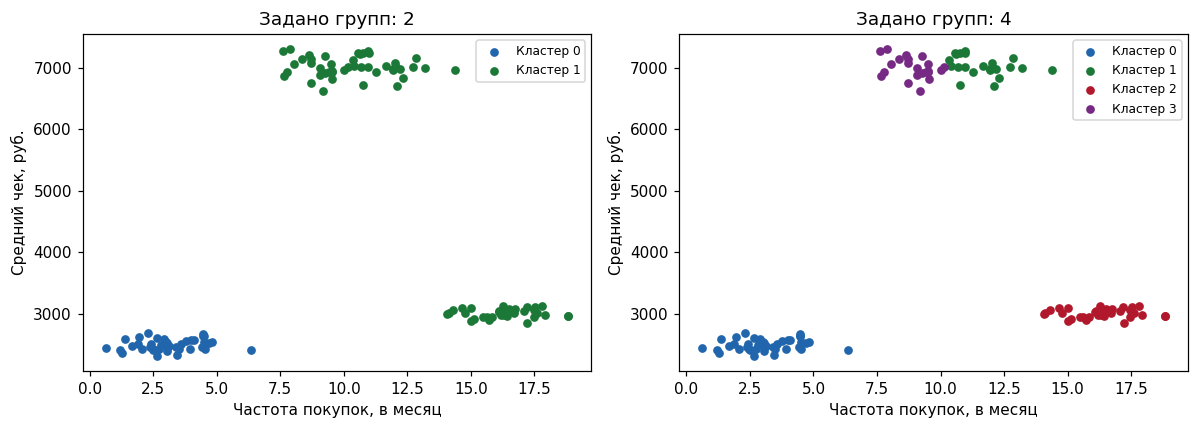

In [26]:
k_rows = []
cluster_variants = {}
for k in [2, 3, 4]:
    variant = Pipeline([
        ('scale', StandardScaler()),
        ('cluster', KMeans(n_clusters=k, n_init=10, random_state=42)),
    ])
    variant_labels = variant.fit_predict(client_features)
    cluster_variants[k] = variant_labels
    k_rows.append({'Число групп': k, 'Внутренний разброс inertia': variant.named_steps['cluster'].inertia_})
display(pd.DataFrame(k_rows).set_index('Число групп'))

palette = ['#2166ac', '#1b7837', '#b2182b', '#762a83']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, [2, 4]):
    for cluster_number in range(k):
        mask = cluster_variants[k] == cluster_number
        ax.scatter(
            client_features.loc[mask, 'Частота покупок, в месяц'],
            client_features.loc[mask, 'Средний чек, руб.'],
            color=palette[cluster_number], s=22, label=f'Кластер {cluster_number}',
        )
    ax.set_title(f'Задано групп: {k}')
    ax.set_xlabel('Частота покупок, в месяц')
    ax.set_ylabel('Средний чек, руб.')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `k_rows = []` создаёт список строк, `cluster_variants = {}` — пустой словарь. Цикл `for k in [2, 3, 4]` каждый раз создаёт новый `Pipeline` из `StandardScaler` и `KMeans` с текущим `n_clusters=k`. `n_init=10`, `random_state=42` имеют прежний смысл.
- `fit_predict(...)` обучает очередной вариант. `cluster_variants[k] = variant_labels` сохраняет метки под числовым ключом. `.named_steps['cluster'].inertia_` читает внутренний критерий обученной группировки. `.append({...})` добавляет строку, `pd.DataFrame(...)`, `.set_index(...)`, `display(...)` показывают таблицу.
- `plt.subplots(...)` создаёт два графика. `zip(axes, [2, 4])` выбирает область и значение `k`. Вложенный цикл `for cluster_number in range(k)` рисует все группы этого варианта: отступы показывают, какой цикл управляет каждой строкой.
- `cluster_variants[k]` выбирает массив меток, `==` создаёт маску, `.loc[...]` выбирает точки. `palette[cluster_number]` выбирает цвет по позиции. `scatter(...)` рисует группу, строки `f'...'` подставляют номер в подписи.
- `set_title`, `set_xlabel`, `set_ylabel`, `legend`, `tight_layout`, `plt.show` оформляют рисунок.

При двух центрах приходится объединить часть разных облаков. При четырёх один из компактных участков может разделиться. Более низкий внутренний разброс четырёх групп сам по себе не доказывает, что четыре сегмента полезнее трёх. Число групп в реальной задаче нужно обосновывать, а не просто увеличивать.

В таблице внутренний разброс снижается примерно со 105,376 при двух группах до 8,181 при трёх и 5,269 при четырёх. На рисунке с двумя группами объединены облако с высоким чеком и облако частых покупок с меньшим чеком. При четырёх группах облако высокого чека разделено на две части. Дополнительное уменьшение критерия не отвечает на вопрос, нужно ли такое разделение для применения.

Проверим геометрическое ограничение K-Means на уже знакомых изогнутых полосах. Используем только обучающие координаты классификационного примера, но не передадим их классы в обучение кластеризации. Слева покажем известные учебные классы для понимания формы, справа — найденные две группы.

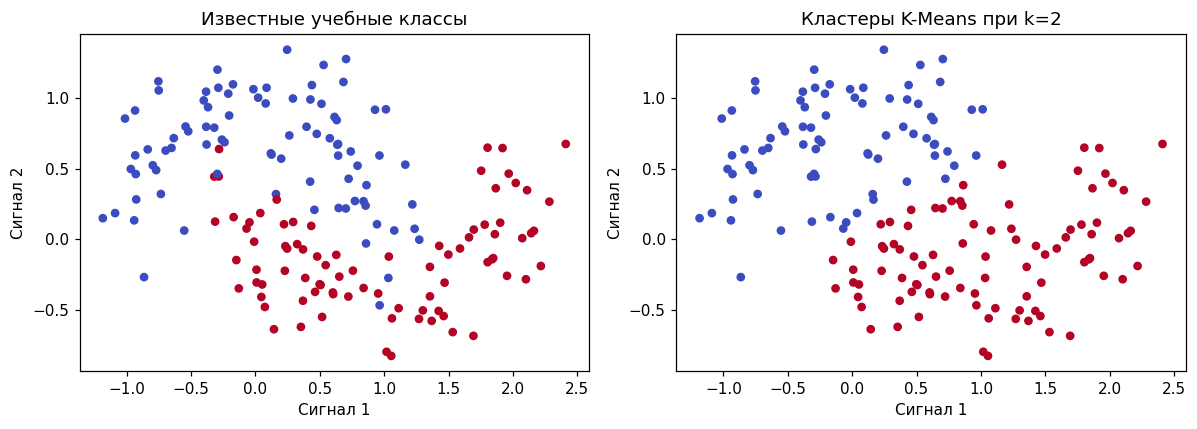

In [27]:
curved_clustering = Pipeline([
    ('scale', StandardScaler()),
    ('cluster', KMeans(n_clusters=2, n_init=10, random_state=42)),
])
curved_labels = curved_clustering.fit_predict(X_class_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labels, title in zip(
    axes,
    [y_class_train.to_numpy(), curved_labels],
    ['Известные учебные классы', 'Кластеры K-Means при k=2'],
):
    ax.scatter(X_class_train['Сигнал 1'], X_class_train['Сигнал 2'], c=labels, cmap='coolwarm', s=22)
    ax.set_title(title)
    ax.set_xlabel('Сигнал 1')
    ax.set_ylabel('Сигнал 2')
fig.tight_layout()
plt.show()

**Разбор кода и результата.**

- `Pipeline`, `StandardScaler` и `KMeans` создают отдельный вариант для двух центров. `fit_predict(X_class_train)` получает только признаки. Переменная `y_class_train` в этом вызове отсутствует; знания о правильных классах кластеризатор не получает.
- `plt.subplots(...)` создаёт две области. `zip(...)` сопоставляет каждой области массив цветов и заголовок. `y_class_train.to_numpy()` возвращает известные классы в текущем порядке строк; `curved_labels` содержит номера кластеров в том же порядке.
- `scatter(..., c=labels, cmap='coolwarm', s=22)` использует числовой массив для выбора цвета каждой точки. `set_title`, `set_xlabel`, `set_ylabel`, `tight_layout` и `plt.show` подписывают и показывают рисунок.

K-Means предпочитает разделение по близости к центрам и не повторяет изгиб каждой полосы. Номера кластеров могут быть переставлены относительно кодов известных классов: одинаковый цвет на двух панелях не означает доказанного соответствия. Даже переименование номеров не исправит различие формы групп.

Это не ошибка выполнения и не доказательство отсутствия структуры. Это пример несоответствия формы групп возможностям конкретного алгоритма. Наличие двух известных классов не гарантирует, что K-Means с двумя центрами восстановит их по координатам.

## 9. Опорная таблица для чтения моделей

| Модель | Что читаем после обучения | На что обращаем внимание |
|---|---|---|
| `LinearRegression` | `coef_`, `intercept_`, числовой `predict` | Ограничение общей линейной зависимости, единицы признаков, поведение за границами обучения |
| `LogisticRegression` | `classes_`, `coef_`, `predict_proba` | Порядок классов, масштаб коэффициентов, ограничение линейной границы |
| `DecisionTreeClassifier` / `DecisionTreeRegressor` | Структура узлов, листья, `apply`, `predict` | Читаемость правил и сложность отдельного дерева |
| `RandomForestClassifier` / `RandomForestRegressor` | `estimators_`, итоговый `predict` | Разнообразие деревьев, их ограничения, усреднение ответов или оценок |
| `GradientBoostingClassifier` / `GradientBoostingRegressor` | Итоговый ответ и промежуточные ответы этапов | Зависимость этапов, совместное действие числа этапов и `learning_rate` |
| `KMeans` | `cluster_centers_`, `labels_`, `inertia_`, `predict` | Заданное число групп, масштаб признаков, форма групп, произвольность номеров |

Линейная модель может быть понятным начальным ориентиром, дерево — читаемым набором условий, лес — способом объединить разнообразные деревья, бустинг — способом постепенно уточнять общий ответ. Их выбор нужно связывать с данными и сценарием применения. Сложность сама по себе не делает модель полезнее.

K-Means решает другую задачу: выдаёт группы без готовых ответов. Его номера не следует сравнивать с классами как обычные предсказания классификатора. Для новых объектов он назначает ближайший из уже обученных центров, даже если объект необычен.

В материале все наборы маленькие, признаки числовые, а настройки демонстрационные. Для реального выбора модели нужны подготовка и схема проверки из предыдущих тем. Интерпретация коэффициента, листа или центра описывает поведение обученного объекта и не заменяет проверку на новых данных.

### Официальные справочные страницы

Дополнительные сведения о методах и параметрах: [линейные модели](https://scikit-learn.org/1.8/modules/linear_model.html), [деревья решений](https://scikit-learn.org/1.8/modules/tree.html), [случайный лес и градиентный бустинг](https://scikit-learn.org/1.8/modules/ensemble.html), [K-Means](https://scikit-learn.org/1.8/modules/clustering.html#k-means). Ссылки ведут на документацию scikit-learn 1.8; версия установленного пакета напечатана в начале ноутбука. Интернет для выполнения примеров не нужен.